# ML Assignment 2 — Heart Disease Prediction (Four Input Attributes)

**Live application:** [ML Assignment 2](https://sp24-bse-149-ml-assignment-2.streamlit.app/)

Project: ML Assignment 2 — Task 2

This notebook mirrors the Titanic workflow, but uses exactly four input attributes from the UCI Heart Disease dataset: `age`, `sex`, `cp` (chest pain type), and `thalach` (maximum heart rate achieved). The target is converted to a binary label: `num = 0` means no disease; `num = 1, 2, 3, 4` means disease present, following UCI's stated experimental framing.

**Dataset source:** UCI Machine Learning Repository, Heart Disease, https://archive.ics.uci.edu/dataset/45/heart+disease

**Medical disclaimer:** this is a classroom ML exercise on a small historical dataset. It is not a diagnostic tool and must not be used for medical decisions.

## Step 1 — Import libraries

In [1]:
from pathlib import Path
import pickle
import urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report, ConfusionMatrixDisplay

CURRENT_DIR = Path.cwd()
BASE_DIR = CURRENT_DIR if (CURRENT_DIR / "data").exists() else CURRENT_DIR.parent
DATA_DIR = BASE_DIR / "data"
DATA_DIR.mkdir(exist_ok=True)
DATA_PATH = DATA_DIR / "heart_disease.csv"
RAW_DATA_URL = "https://archive.ics.uci.edu/ml/machine-learning-databases/heart-disease/processed.cleveland.data"
MODEL_PATH = BASE_DIR / "heart_disease_model.pkl"

## Step 2 — Download and load the UCI dataset

The processed Cleveland file has 14 columns and 303 records. The raw file has no header row; a question mark (`?`) denotes a missing value. This cell saves a local CSV copy for your submission folder.

In [2]:
columns = [
    "age", "sex", "cp", "trestbps", "chol", "fbs", "restecg",
    "thalach", "exang", "oldpeak", "slope", "ca", "thal", "num"
]

if not DATA_PATH.exists():
    try:
        raw_df = pd.read_csv(RAW_DATA_URL, header=None, names=columns, na_values="?")
        raw_df.to_csv(DATA_PATH, index=False)
        print("Downloaded and saved dataset to:", DATA_PATH)
    except Exception as error:
        raise RuntimeError(
            "Could not download the UCI dataset. Check your internet connection, "
            "then re-run this cell. You can also download processed.cleveland.data "
            "from the UCI page and place the renamed file at data/heart_disease.csv "
            "only after converting it to the 14-column CSV layout documented in this notebook."
        ) from error

# Read our normalized local CSV copy.
df = pd.read_csv(DATA_PATH, na_values="?")
print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (303, 14)


    age  sex   cp  trestbps   chol  fbs  ...  exang  oldpeak  slope   ca  thal  num
0  63.0  1.0  1.0     145.0  233.0  1.0  ...    0.0      2.3    3.0  0.0   6.0    0
1  67.0  1.0  4.0     160.0  286.0  0.0  ...    1.0      1.5    2.0  3.0   3.0    2
2  67.0  1.0  4.0     120.0  229.0  0.0  ...    1.0      2.6    2.0  2.0   7.0    1
3  37.0  1.0  3.0     130.0  250.0  0.0  ...    0.0      3.5    3.0  0.0   3.0    0
4  41.0  0.0  2.0     130.0  204.0  0.0  ...    0.0      1.4    1.0  0.0   3.0    0

[5 rows x 14 columns]

## Step 3 — Understand and preprocess the data

First inspect the dataset, missing values, types, and target distribution. The assignment constraint is to use only four input attributes; other clinical columns are not used as model inputs.

In [3]:
print("Data types:")
print(df.dtypes)
print("\nMissing values per column:")
print(df.isna().sum())
print("\nTarget distribution (raw num values 0-4):")
display(df["num"].value_counts(dropna=False).sort_index())

Data types:
age         float64
sex         float64
cp          float64
trestbps    float64
chol        float64
fbs         float64
restecg     float64
thalach     float64
exang       float64
oldpeak     float64
slope       float64
ca          float64
thal        float64
num           int64
dtype: object

Missing values per column:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
num         0
dtype: int64

Target distribution (raw num values 0-4):


num
0    164
1     55
2     36
3     35
4     13
Name: count, dtype: int64

In [4]:
feature_columns = ["age", "sex", "cp", "thalach"]
target_column = "num"

# Convert selected columns and target to numeric; invalid values become NaN.
for column in feature_columns + [target_column]:
    df[column] = pd.to_numeric(df[column], errors="coerce")

# Only the selected fields and target are required for this assignment.
data = df[feature_columns + [target_column]].dropna().copy()
data["sex"] = data["sex"].astype(int)
data["cp"] = data["cp"].astype(int)
data[target_column] = data[target_column].astype(int)

# Binary classification: 0 = no disease; 1-4 = disease present.
data["DiseaseStatus"] = np.where(data[target_column] == 0, "No disease", "Disease present")
print("Rows available after cleaning:", len(data))
print("Selected attributes:", feature_columns)
display(data[feature_columns + ["DiseaseStatus"]].head())

Rows available after cleaning: 303
Selected attributes: ['age', 'sex', 'cp', 'thalach']


    age  sex  cp  thalach    DiseaseStatus
0  63.0    1   1    150.0       No disease
1  67.0    1   4    108.0  Disease present
2  67.0    1   4    129.0  Disease present
3  37.0    1   3    187.0       No disease
4  41.0    0   2    172.0       No disease

### Understand the four selected attributes

| Attribute | Meaning | Data treatment |
|---|---|---|
| `age` | Age in years | Numeric input |
| `sex` | Dataset code: 0=female, 1=male | Label-encoded category |
| `cp` | Chest pain type: 1=typical, 2=atypical, 3=non-anginal, 4=asymptomatic | Label-encoded category |
| `thalach` | Maximum heart rate achieved | Numeric input |
| `DiseaseStatus` | No disease if `num=0`; disease present if `num>0` | Prediction target |

## Step 4 — Feature extraction

Use no more than the four selected feature columns. `DiseaseStatus` is the output label.

In [5]:
X_raw = data[feature_columns].copy()
y_text = data["DiseaseStatus"].astype(str)
print("X shape:", X_raw.shape)
print("y shape:", y_text.shape)

X shape: (303, 4)
y shape: (303,)


## Step 5 — Label encoding

`sex` and `cp` are categorical codes, while `age` and `thalach` remain numeric. The target labels are also encoded. The fitted encoders are saved with the classifier for use in the deployed app.

In [6]:
categorical_features = ["sex", "cp"]
feature_encoders = {}
X = X_raw.copy()
for column in categorical_features:
    encoder = LabelEncoder()
    # Make the category representation stable between training and app input.
    values = X[column].astype(int).astype(str)
    X[column] = encoder.fit_transform(values)
    feature_encoders[column] = encoder

# Keep numeric health measurements numeric.
X["age"] = X["age"].astype(float)
X["thalach"] = X["thalach"].astype(float)

target_encoder = LabelEncoder()
y = target_encoder.fit_transform(y_text)
print("Encoded feature sample:")
display(X.head())
print("Target mapping:", {label: int(target_encoder.transform([label])[0]) for label in target_encoder.classes_})

Encoded feature sample:
Target mapping: {'Disease present': 0, 'No disease': 1}


    age  sex  cp  thalach
0  63.0    1   0    150.0
1  67.0    1   3    108.0
2  67.0    1   3    129.0
3  37.0    1   2    187.0
4  41.0    0   1    172.0

## Step 6 — Training phase

Split the data using a fixed random seed and stratify by the target so the class ratio is approximately preserved. Train an SVC as in the Titanic workflow.

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=0, stratify=y
)
print("Training records:", len(X_train))
print("Testing records:", len(X_test))

model = SVC(gamma="auto", random_state=0)
model.fit(X_train, y_train)
print("Training complete.")

Training records: 242
Testing records: 61
Training complete.


In [8]:
model_bundle = {
    "model": model,
    "feature_columns": feature_columns,
    "feature_encoders": feature_encoders,
    "target_encoder": target_encoder,
    "categorical_features": categorical_features,
    "dataset_file": "data/heart_disease.csv",
    "target_definition": "num == 0: No disease; num > 0: Disease present",
}
with open(MODEL_PATH, "wb") as file:
    pickle.dump(model_bundle, file)
print("Saved trained model bundle to:", MODEL_PATH)

Saved trained model bundle to: C:\Users\hasee\Downloads\ML A2 THEORY\Final_Submission\heart_disease_model.pkl


## Step 7 — Testing and evaluation

Evaluate with accuracy, precision, recall, F1-score and a confusion matrix. As the dataset is small and only four attributes are used, results may vary by split and should not be interpreted as clinical performance.

In [9]:
y_pred = model.predict(X_test)
print(f"Accuracy:  {accuracy_score(y_test, y_pred):.3f}")
print(f"Precision: {precision_score(y_test, y_pred, zero_division=0):.3f}")
print(f"Recall:    {recall_score(y_test, y_pred, zero_division=0):.3f}")
print(f"F1-score:  {f1_score(y_test, y_pred, zero_division=0):.3f}")
print("\nClassification report:")
print(classification_report(y_test, y_pred, target_names=target_encoder.classes_, zero_division=0))

Accuracy:  0.639
Precision: 0.667
Recall:    0.667
F1-score:  0.667

Classification report:
                 precision    recall  f1-score   support

Disease present       0.61      0.61      0.61        28
     No disease       0.67      0.67      0.67        33

       accuracy                           0.64        61
      macro avg       0.64      0.64      0.64        61
   weighted avg       0.64      0.64      0.64        61



Heart_Disease_Prediction.ipynb:cell19:5: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


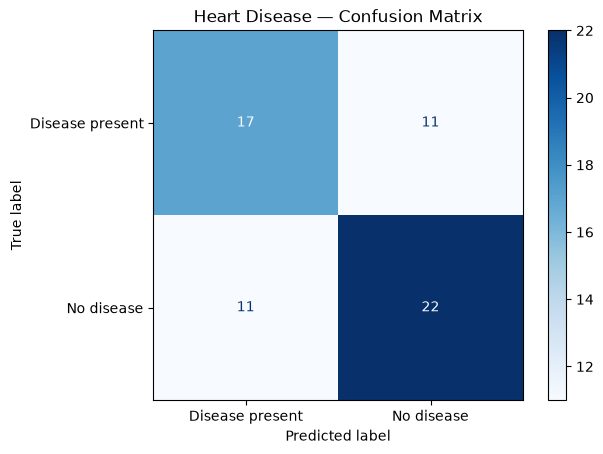

In [10]:
cm = confusion_matrix(y_test, y_pred)
cm_display = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=target_encoder.classes_)
cm_display.plot(cmap="Blues", values_format="d")
plt.title("Heart Disease — Confusion Matrix")
plt.show()

## Step 8 — Application phase: predict for one example

Edit the values below to try different inputs. `sex` uses 0=female and 1=male; `cp` uses 1, 2, 3 or 4 as documented above.

In [11]:
new_patient = {"age": 54, "sex": 1, "cp": 4, "thalach": 150}
new_row = pd.DataFrame([new_patient], columns=feature_columns)
for column in categorical_features:
    new_row[column] = feature_encoders[column].transform(new_row[column].astype(int).astype(str))
new_row["age"] = new_row["age"].astype(float)
new_row["thalach"] = new_row["thalach"].astype(float)
prediction_code = model.predict(new_row)[0]
prediction = target_encoder.inverse_transform([prediction_code])[0]
print("Input patient attributes:", new_patient)
print("Model output:", prediction)

Input patient attributes: {'age': 54, 'sex': 1, 'cp': 4, 'thalach': 150}
Model output: No disease


## Step 9 — Feedback and potential improvements

Potential improvements include trying cross-validation, comparing multiple algorithms, collecting more representative data, checking calibration, and asking domain experts to review the features and output. Because this assignment limits the model to four inputs, it intentionally excludes many variables used in published heart-disease experiments.

## Step 10 — Deploy to Streamlit Community Cloud

1. Run every cell from top to bottom. This downloads/saves `data/heart_disease.csv` and creates `heart_disease_model.pkl` in the project root.
2. Run the Titanic notebook as well to create `titanic_model.pkl`.
3. Place `app.py`, `model_utils.py`, `requirements.txt`, the `data/` folder, and both model files in a GitHub repository you control.
4. Sign in at https://share.streamlit.io/, create an app using `app.py`, and wait for its build to finish.
5. Test the Titanic and Heart Disease tabs. Copy the public URL into the deployment link at the very top of this notebook and keep it in the submitted copy.

The app is for educational demonstration only, not medical advice or diagnosis.